# The testing is informative for defensive linemen; the decisions are not

**NFL Big Data Bowl 2027 — public analysis notebook**

This notebook reproduces the core competition-data results: the 10 Hz Combine movement composite, position-specific performance models, role persistence, and the week-to-week check. The cost-risk tables are derived public-data aggregates embedded for self-containment; the writeup and repository carry the full derivation.

- **The Combine signal is position-specific.** DL +0.734 (95% CI 0.461–1.007), WR +0.366 (p=0.084), OL +0.058, TE +0.093; interaction p=0.0004. The pooled +0.299 is a defensive-line result; the standardized effect is 0.185, not one-third.
- **Playing time is sticky and draft-driven.** Next-season role follows current role (+0.606) and draft capital (+0.785), not performance (−0.011); the within-player change is −0.095 (p=0.11).
- **The cap pays for performance.** On the full 909-player ledger, performance enters at +0.328 (95% CI 0.264–0.392) and +0.143 (0.078–0.208) with role. The 153-player draft-matched model fades to +0.040; it is a rookie-scale sensitivity, not the headline. The salary performance measure is nflverse public production, not the NGS residual.
- **The allocation gap is systematic.** Performance minus role: late picks/UDFAs +0.59, early picks −0.92 in the full 233-row sample; the strict top-performance/bottom-role quartile tail is 13 player-seasons.
- **All analyses are exploratory/post-hoc.** The preregistered RJF/Yellow Square null pattern is in the repository appendix. Competition data is CC BY-NC 4.0; do not redistribute.

Self-contained reconstruction: Combine +0.295 (p<0.001), role −0.034 (n=195); full pipeline +0.299 and −0.019 (n=192). The small differences come from the reconstruction's role-standardization universe, not sampling variation.


In [1]:

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score

KAGGLE = Path("/kaggle/input/nfl-big-data-bowl-2027")
def _local_data():
    for p in [Path.cwd(), *Path.cwd().parents]:
        cand = p / "data" / "raw"
        if cand.exists():
            return cand
    return None
LOCAL = _local_data()
if KAGGLE.exists():
    DATA = KAGGLE
elif LOCAL is not None:
    DATA = LOCAL
else:
    import kagglehub
    root = Path(kagglehub.competition_download("nfl-big-data-bowl-2027"))
    DATA = next(root.rglob("players.csv")).parent
print("Data:", DATA)

players = pd.read_csv(DATA / "players.csv")
combine = pd.read_csv(DATA / "combine_results.csv")
games = pd.read_csv(DATA / "games.csv")
career = pd.read_csv(DATA / "player_career_successes.csv")
games["home_team_abbr"] = games["home_team_abbr"].replace({"LA": "LAR"})
games["visitor_team_abbr"] = games["visitor_team_abbr"].replace({"LA": "LAR"})
header = pd.read_csv(DATA / "player_play.csv", nrows=0).columns
usecols = [c for c in [
    "game_id","play_id","team_abbr","nfl_id","lined_up_position","possession_team",
    "player_get_off","pressure_allowed","pass_result","separation_at_pass_forward",
    "route_ran","target","cushion","down","yards_to_go","pass_length",
    "in_motion_at_ball_snap","blitzing","pass_rushers_encountered","dropback_duration",
    "coverage_assignment","receiver_alignment","team_coverage_man_zone",
    "team_coverage_type","yardline_number","expected_points",
] if c in header]
pp = pd.read_csv(DATA / "player_play.csv", usecols=usecols)
pp = pp.merge(games[["game_id","season","week","season_type"]], on="game_id", how="left")
pp = pp[(pp["season_type"] == "REG") & pp["nfl_id"].isin(players["nfl_id"])].copy()
pp["team_abbr"] = pp["team_abbr"].replace({"LA": "LAR"})
pp["nfl_position"] = pp["nfl_id"].map(players.set_index("nfl_id")["nfl_position"])
group_map = {"WR":"WR","TE":"TE","CB":"DB","SS":"DB","FS":"DB","DB":"DB",
             "T":"OL","G":"OL","C":"OL","DE":"DL","DT":"DL","NT":"DL","OLB":"DL",
             "ILB":"LB","MLB":"LB"}
pp["position_group"] = pp["nfl_position"].map(group_map).fillna("OTHER")
print(pp.shape)


Data: /home/patrick/NFL/data/raw


(249269, 31)


## Position-specific performance residuals

In [2]:

GROUPS = {"DL":{"DE","DT","NT","OLB"},"WR":{"WR"},"TE":{"TE"},"OL":{"T","G","C"},
          "DB":{"CB","SS","FS","DB"},"LB":{"ILB","MLB"}}
NUM = ["yards_to_go","pass_length","cushion","dropback_duration","pass_rushers_encountered",
       "yardline_number","expected_points"]
CAT = ["route_ran","team_coverage_man_zone","team_coverage_type","down",
       "in_motion_at_ball_snap","blitzing","coverage_assignment","receiver_alignment","season"]

def outcome(group, df):
    if group == "DL": return -df["player_get_off"].astype(float)
    if group in {"WR","TE"}: return df["separation_at_pass_forward"]
    if group == "OL": return -df["pressure_allowed"].astype(float)
    if group == "DB": return -df["pass_result"].map({"C":1.0,"I":0.0,"IN":0.0})
    return -df["player_get_off"].astype(float)

def model():
    num = Pipeline([("imp",SimpleImputer(strategy="median",add_indicator=True)),("sc",StandardScaler())])
    cat = Pipeline([("imp",SimpleImputer(strategy="most_frequent")),
                    ("oh",OneHotEncoder(handle_unknown="ignore",sparse_output=True))])
    pre = ColumnTransformer([("num",num,NUM),("cat",cat,CAT)],sparse_threshold=1.0)
    return Pipeline([("pre",pre),("ridge",Ridge(alpha=1.0))])

def residuals(group):
    d = pp[pp["nfl_id"].isin(players.loc[players["nfl_position"].isin(GROUPS[group]),"nfl_id"])].copy()
    d["y"] = outcome(group, d)
    d = d.dropna(subset=["y"])
    if len(d) < 50: return pd.DataFrame()
    X, y, g = d[NUM+CAT], d["y"].to_numpy(), d["nfl_id"].to_numpy()
    r = np.full(len(d), np.nan)
    for tr, te in GroupKFold(5).split(X, y, g):
        m = model().fit(X.iloc[tr], y[tr])
        r[te] = y[te] - m.predict(X.iloc[te])
    d["residual"] = r
    season = d.groupby(["nfl_id","season"])["residual"].agg(raw_mean="mean",n_plays="count",within_var="var").reset_index()
    season["within_var"] = season["within_var"].fillna(0)
    noise = season["within_var"] / season["n_plays"]
    tau2 = max(float(season["raw_mean"].var(ddof=0) - noise.mean()), 0.0)
    season["shrunk_mean"] = season["raw_mean"]*tau2/(tau2+noise) if tau2 > 0 else 0.0
    season["group"] = group
    return season

perf_list = []
for g in GROUPS:
    s = residuals(g)
    if len(s):
        perf_list.append(s)
perf = pd.concat(perf_list, ignore_index=True)
perf = perf.rename(columns={"raw_mean":"perf_raw","n_plays":"perf_n","within_var":"perf_var","shrunk_mean":"perf_shrunk"})
print(perf.groupby("group").size())


group
DB    161
DL    175
OL    156
TE     63
WR    149
dtype: int64


## Player-season role panel

In [3]:

pp["is_defense"] = pp["team_abbr"] != pp["possession_team"]
team = pp.groupby(["nfl_id","season","team_abbr"]).size().reset_index(name="team_snaps")
n_teams = team.groupby(["nfl_id","season"])["team_abbr"].nunique().rename("n_teams").reset_index()
primary = (team.sort_values("team_snaps").drop_duplicates(["nfl_id","season"],keep="last")
           [["nfl_id","season","team_abbr"]].rename(columns={"team_abbr":"primary_team"}))
ps = pp.groupby(["nfl_id","season"]).agg(
    snaps=("game_id","size"), games=("game_id","nunique"),
    pass_rush_plays=("player_get_off",lambda x:x.notna().sum()),
    pass_block_plays=("pressure_allowed",lambda x:x.notna().sum()),
    coverage_plays=("coverage_assignment",lambda x:x.notna().sum()),
    routes=("route_ran",lambda x:x.notna().sum())).reset_index()
ps = ps.merge(primary, on=["nfl_id","season"]).merge(n_teams, on=["nfl_id","season"])
ps["position_group"] = ps["nfl_id"].map(pp.drop_duplicates("nfl_id").set_index("nfl_id")["position_group"])
ps = ps.merge(perf[["nfl_id","season","perf_shrunk","perf_n"]], on=["nfl_id","season"], how="left")
ps["role_pg"] = ps["snaps"] / ps["games"].replace(0,np.nan)
ps["role_pass"] = ps[["pass_rush_plays","routes","pass_block_plays","coverage_plays"]].max(axis=1) / ps["games"].replace(0,np.nan)
room = ps.groupby(["season","primary_team","position_group"])["snaps"].transform("sum")
ps["role_share"] = ps["snaps"] / room.replace(0,np.nan)
for col, name in [("role_pg","role_z"),("role_pass","role_pass_z"),("role_share","role_share_z")]:
    ps[name] = ps.groupby(["position_group","season"])[col].transform(
        lambda x:(x-x.mean())/x.std(ddof=0) if x.std(ddof=0)>0 else x*0)
ps["perf_z"] = ps.groupby(["position_group","season"])["perf_shrunk"].transform(
    lambda x:(x-x.mean())/x.std(ddof=0) if x.std(ddof=0)>0 else x*0)
ps = ps.sort_values(["nfl_id","season"])
ps["next_role"] = ps.groupby("nfl_id")["role_z"].shift(-1)
ps["next2_role"] = ps.groupby("nfl_id")["role_z"].shift(-2)
ps["next_season"] = ps.groupby("nfl_id")["season"].shift(-1)
ps["next2_season"] = ps.groupby("nfl_id")["season"].shift(-2)
ps = ps.merge(players[["nfl_id","display_name","draft_year","draft_overall_pick"]], on="nfl_id", how="left")
ps = ps.merge(combine[["nfl_id","ngs_final_score","ngs_college_production_score","ngs_athleticism_score"]], on="nfl_id", how="left")
# Draft-capital percentile on unique players, not player-seasons.
pu = players.merge(combine[["nfl_id","ngs_final_score","ngs_college_production_score","ngs_athleticism_score"]], on="nfl_id", how="left")
pu["position_group"] = pu["nfl_position"].map(group_map).fillna("OTHER")
pu["B_draft"] = 0.0
for (yr, pos), idx in pu.groupby(["draft_year","position_group"]).groups.items():
    sub = pu.loc[idx]; picks = sub["draft_overall_pick"]; r = picks.rank(method="average", ascending=False)
    pu.loc[idx,"B_draft"] = (r-1)/max(len(sub)-1,1)
    pu.loc[sub.index[picks.isna()],"B_draft"] = 0.0
pu["B_draft"] = pu["B_draft"].clip(0,1)
ps = ps.merge(pu[["nfl_id","B_draft"]], on="nfl_id", how="left")
for col in ["ngs_final_score","ngs_college_production_score"]:
    ps[col+"_z"] = (ps[col]-ps[col].mean())/ps[col].std(ddof=0)
ps["prestige_nodraft"] = ps[["ngs_final_score_z","ngs_college_production_score_z"]].mean(axis=1)
ps = ps.merge(career[["nfl_id","career_offensive_snaps","career_defensive_snaps",
                      "career_special_teams_snaps","career_games_active","career_games_started"]], on="nfl_id", how="left")
ps["career_snaps"] = ps[["career_offensive_snaps","career_defensive_snaps","career_special_teams_snaps"]].sum(axis=1)
ps["season_c"] = ps["season"].astype(str)
print(ps.shape)


(722, 41)


## Role persistence and within-player validation

In [4]:

t1 = ps[(ps["next_season"] == ps["season"]+1) & ps["next_role"].notna()].copy()
t2 = ps[(ps["next2_season"] == ps["season"]+2) & ps["next2_role"].notna()].copy()
fe = " + C(position_group) + C(season_c)"
base = t1[t1["position_group"] != "DB"].dropna(
    subset=["role_z","perf_z","B_draft","prestige_nodraft","season_c","position_group","primary_team"]).copy()
t2 = t2[t2["position_group"] != "DB"].dropna(
    subset=["role_z","perf_z","B_draft","season_c","position_group"]).copy()

def fit(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups":data["nfl_id"]})

concurrent = fit(f"role_z ~ perf_z + B_draft + prestige_nodraft{fe}", base)
base["role_gap"] = concurrent.resid
next1 = fit(f"next_role ~ role_z + perf_z + B_draft{fe}", base)
next1p = fit(f"next_role ~ perf_z + B_draft + prestige_nodraft{fe}", base)
next2 = fit(f"next2_role ~ role_z + perf_z + B_draft{fe}", t2)
base["team_role_mean"] = base.groupby(["primary_team","season"])["role_z"].transform("mean")
base = base.dropna(subset=["team_role_mean"]).copy()
next1_team = fit(f"next_role ~ role_z + perf_z + B_draft + team_role_mean{fe}", base)
sens = {}
for role_col, label in [("role_pass_z","pass-play role"),("role_share_z","cohort role share")]:
    sub = t1[t1["position_group"] != "DB"].dropna(
        subset=[role_col,"perf_z","B_draft","next_role","season_c","position_group"]
    )
    sens[label] = fit(f"next_role ~ {role_col} + perf_z + B_draft{fe}", sub)
dd = ps[ps["position_group"] != "DB"].sort_values(["nfl_id","season"]).copy()
dd["d_role"] = dd.groupby("nfl_id")["role_z"].diff()
dd["d_perf"] = dd.groupby("nfl_id")["perf_z"].diff()
dd["d_next"] = dd.groupby("nfl_id")["season"].diff()
diff = dd[dd["d_next"] == 1].dropna(subset=["d_role","d_perf"])
diff_fit = fit("d_role ~ d_perf", diff)

def show(fit, label, terms):
    print(label)
    for term in terms:
        if term not in fit.params: continue
        ci = fit.conf_int().loc[term]
        print(f"  {term}: {fit.params[term]:+.3f} ({ci[0]:+.3f}, {ci[1]:+.3f}) p={fit.pvalues[term]:.3g}")

show(concurrent, "Concurrent role", ["perf_z","B_draft","prestige_nodraft"])
show(next1, "Next role", ["role_z","perf_z","B_draft"])
show(next1p, "Next role (performance only)", ["perf_z","B_draft","prestige_nodraft"])
show(next2, "Role at t+2", ["role_z","perf_z","B_draft"])
show(next1_team, "Next role (team control)", ["role_z","perf_z","B_draft","team_role_mean"])
show(diff_fit, "Within-player change", ["d_perf"])

# Position replication and role-measure sensitivity tables for figures.
pos_rows = []
for g, sub in t1.groupby("position_group"):
    if len(sub) < 25:
        continue
    if g == "DB":
        sub = sub.dropna(subset=["role_z","B_draft","next_role"])
        f = fit("next_role ~ role_z + B_draft", sub)
        pos_rows.append({"position":g,"n":len(sub),
                         "role":f.params["role_z"],"role_lo":f.conf_int().loc["role_z",0],"role_hi":f.conf_int().loc["role_z",1],
                         "perf":np.nan,"perf_lo":np.nan,"perf_hi":np.nan,
                         "draft":f.params["B_draft"],"draft_lo":f.conf_int().loc["B_draft",0],"draft_hi":f.conf_int().loc["B_draft",1]})
    else:
        sub = sub.dropna(subset=["role_z","perf_z","B_draft","next_role"])
        f = fit("next_role ~ role_z + perf_z + B_draft", sub)
        pos_rows.append({"position":g,"n":len(sub),
                         "role":f.params["role_z"],"role_lo":f.conf_int().loc["role_z",0],"role_hi":f.conf_int().loc["role_z",1],
                         "perf":f.params["perf_z"],"perf_lo":f.conf_int().loc["perf_z",0],"perf_hi":f.conf_int().loc["perf_z",1],
                         "draft":f.params["B_draft"],"draft_lo":f.conf_int().loc["B_draft",0],"draft_hi":f.conf_int().loc["B_draft",1]})
pos_df = pd.DataFrame(pos_rows)
sens_rows = []
for label, fit_obj, role_term in [
    ("Raw snaps", next1, "role_z"),
    ("Pass-play role", sens["pass-play role"], "role_pass_z"),
    ("Cohort role share", sens["cohort role share"], "role_share_z"),
    ("Team control", next1_team, "role_z"),
]:
    for key, term in [("role", role_term), ("performance", "perf_z"), ("draft", "B_draft")]:
        if term not in fit_obj.params:
            continue
        ci = fit_obj.conf_int().loc[term]
        sens_rows.append({"model": label, "series": key, "coef": fit_obj.params[term],
                          "lo": ci[0], "hi": ci[1]})
sens_df = pd.DataFrame(sens_rows)

# OOF role prediction.
X = base[["role_z","perf_z","B_draft","position_group","season_c"]]
y = base["next_role"]; groups = base["nfl_id"].to_numpy()
oof = np.full(len(base), np.nan); oof_perf = []
for tr, te in GroupKFold(5).split(X, y, groups):
    f = smf.ols("next_role ~ role_z + perf_z + B_draft + C(position_group) + C(season_c)",
                data=base.iloc[tr]).fit()
    oof[te] = f.predict(base.iloc[te]); oof_perf.append(float(f.params["perf_z"]))
print("OOF R2", round(r2_score(y, oof),3), "perf coef range", round(min(oof_perf),3), round(max(oof_perf),3))

# Descriptive tails on reliable samples.
tail = base[base["perf_n"] >= 50].copy()
tail["allocation"] = "mid"
tail.loc[(tail["perf_z"] >= tail["perf_z"].quantile(.75)) & (tail["role_gap"] <= tail["role_gap"].quantile(.25)),
         "allocation"] = "low role / high performance"
tail.loc[(tail["perf_z"] <= tail["perf_z"].quantile(.25)) & (tail["role_gap"] >= tail["role_gap"].quantile(.75)),
         "allocation"] = "high role / low performance"
print(tail.groupby("allocation")[["role_z","perf_z","role_gap","next_role"]].agg(["count","mean"]).round(3))


Concurrent role
  perf_z: -0.129 (-0.246, -0.012) p=0.0309
  B_draft: +1.458 (+0.811, +2.105) p=1.01e-05
  prestige_nodraft: +0.286 (+0.141, +0.431) p=0.000112
Next role
  role_z: +0.624 (+0.527, +0.722) p=4.25e-36
  perf_z: +0.009 (-0.101, +0.119) p=0.871
  B_draft: +0.778 (+0.328, +1.228) p=0.000698
Next role (performance only)
  perf_z: -0.076 (-0.209, +0.057) p=0.262
  B_draft: +1.538 (+0.767, +2.309) p=9.24e-05
  prestige_nodraft: +0.229 (+0.056, +0.402) p=0.0096
Role at t+2
  role_z: +0.435 (+0.205, +0.664) p=0.000205
  perf_z: -0.151 (-0.379, +0.077) p=0.194
  B_draft: +1.273 (+0.373, +2.173) p=0.00555
Next role (team control)
  role_z: +0.682 (+0.565, +0.799) p=3.18e-30
  perf_z: +0.004 (-0.105, +0.114) p=0.938
  B_draft: +0.749 (+0.299, +1.199) p=0.0011
  team_role_mean: -0.196 (-0.418, +0.027) p=0.0851
Within-player change
  d_perf: -0.096 (-0.212, +0.019) p=0.101


OOF R2 0.502 perf coef range -0.024 0.056
                            role_z        perf_z        role_gap         \
                             count   mean  count   mean    count   mean   
allocation                                                                
high role / low performance      9  1.289      9 -1.200        9  1.024   
low role / high performance     13 -0.543     13  1.401       13 -0.635   
mid                            173  0.403    173  0.031      173  0.165   

                            next_role         
                                count   mean  
allocation                                    
high role / low performance         9  0.826  
low role / high performance        13 -0.453  
mid                               173  0.475  


## 10 Hz Combine movement linkage

In [5]:

# Generic 10 Hz Combine movement composite and its linkage.
ct = pd.read_csv(DATA/"combine_tracking.csv", usecols=["event_id","nfl_id","entity_type","time","x","y","s","a","drill_name","attempt"])
ct = ct[(ct.entity_type=="PLAYER") & ct.nfl_id.notna()].copy()
ct["time"] = pd.to_datetime(ct["time"])
ct = ct.sort_values(["event_id","nfl_id","attempt","time"])
g = ct.groupby(["event_id","nfl_id","attempt"])
ct["elapsed"] = (ct["time"]-g["time"].transform("first")).dt.total_seconds()
ct["from_start"] = np.hypot(ct["x"]-g["x"].transform("first"), ct["y"]-g["y"].transform("first"))
def attempt_stats(d):
    d=d.sort_values("time"); e=d["elapsed"].to_numpy(); s=d["s"].to_numpy(); a=d["a"].to_numpy()
    x=d["x"].to_numpy(); y=d["y"].to_numpy(); dist=np.hypot(x-x[0],y-y[0]); path=np.sum(np.hypot(np.diff(x),np.diff(y)))
    hit=np.where(dist>=1)[0]; first=e<=0.5
    return pd.Series({"max_speed":s.max(),"max_accel_first":a[first].max() if first.any() else np.nan,
                      "time_to_1yd":e[hit[0]] if len(hit) else np.nan,
                      "path_eff":min(dist[-1]/path,1.0) if path>0 else np.nan})
att = g.apply(attempt_stats, include_groups=False).reset_index()
att = att.merge(ct[["event_id","nfl_id","attempt","drill_name"]].drop_duplicates(), on=["event_id","nfl_id","attempt"], how="left")
att["position_group"] = att["nfl_id"].map(
    players.drop_duplicates("nfl_id").set_index("nfl_id")["nfl_position"]
).map(group_map).fillna("OTHER")
for col in ["max_speed","max_accel_first","time_to_1yd","path_eff"]:
    att[col]=att.groupby(["drill_name","position_group"])[col].transform(
        lambda x:(x-x.mean())/x.std(ddof=1) if x.std(ddof=1)>0 else x*0)
cm = att.groupby("nfl_id").agg(speed=("max_speed","mean"),accel=("max_accel_first","mean"),
                               time1=("time_to_1yd","mean"),path=("path_eff","mean")).reset_index()
parts = cm[["speed","accel","path"]].copy()
parts["time1"] = -cm["time1"]
parts = parts.apply(lambda x:(x-x.mean())/x.std(ddof=0))
cm["combine_movement"] = parts.mean(axis=1)
print("Combine movement players:", len(cm))

perf_sample = ps.merge(cm, on="nfl_id", how="left").dropna(subset=["combine_movement","perf_z"])
perf_sample = perf_sample[perf_sample["position_group"] != "DB"].copy()
role_sample = base[(base["perf_n"] >= 50) & base["role_gap"].notna()].merge(
    cm, on="nfl_id", how="left").dropna(subset=["combine_movement"])
combine_rows = []
for data, formula, label in [
    (perf_sample,"perf_z ~ combine_movement + B_draft + C(position_group) + C(season_c)","performance"),
    (role_sample,"role_z ~ combine_movement + B_draft + C(position_group) + C(season_c)","role"),
    (role_sample,"role_gap ~ combine_movement + role_z + B_draft + C(position_group)","role gap"),
]:
    f=smf.ols(formula,data=data).fit(cov_type="cluster",cov_kwds={"groups":data["nfl_id"]})
    ci=f.conf_int().loc["combine_movement"]
    combine_rows.append({"outcome":label,"coef":f.params["combine_movement"],"ci_low":ci[0],"ci_high":ci[1],"p":f.pvalues["combine_movement"],"n":len(data)})
    print(label, f"{f.params['combine_movement']:+.3f}", f"({ci[0]:+.3f}, {ci[1]:+.3f})", "p", f"{f.pvalues['combine_movement']:.3g}", "n", len(data))
combine_df = pd.DataFrame(combine_rows)

# Position-specific Combine -> performance models.
print("\nBy position:")
pos_rows = []
for group in ["DL", "WR", "OL", "TE"]:
    sub = perf_sample[perf_sample["position_group"] == group]
    f = smf.ols("perf_z ~ combine_movement + B_draft + C(season_c)", data=sub).fit(
        cov_type="cluster", cov_kwds={"groups": sub["nfl_id"]}
    )
    ci = f.conf_int().loc["combine_movement"]
    pos_rows.append({"position_group": group, "coef": f.params["combine_movement"],
                     "ci_low": ci[0], "ci_high": ci[1], "p": f.pvalues["combine_movement"],
                     "n": len(sub)})
    print(group, f"{f.params['combine_movement']:+.3f}", f"({ci[0]:+.3f}, {ci[1]:+.3f})",
          "p", f"{f.pvalues['combine_movement']:.3g}", "n", len(sub))
position_df = pd.DataFrame(pos_rows)
print(position_df.round(3).to_string(index=False))


Combine movement players: 510
performance +0.295 (+0.150, +0.441) p 6.83e-05 n 543
role -0.034 (-0.207, +0.139) p 0.696 n 195
role gap +0.016 (-0.040, +0.072) p 0.566 n 195

By position:
DL +0.726 (+0.457, +0.995) p 1.21e-07 n 175
WR +0.366 (-0.049, +0.780) p 0.0838 n 149
OL +0.058 (-0.114, +0.229) p 0.509 n 156
TE +0.076 (-0.237, +0.388) p 0.635 n 63
position_group  coef  ci_low  ci_high     p   n
            DL 0.726   0.457    0.995 0.000 175
            WR 0.366  -0.049    0.780 0.084 149
            OL 0.058  -0.114    0.229 0.509 156
            TE 0.076  -0.237    0.388 0.635  63


## Figures

combine_linkage.png


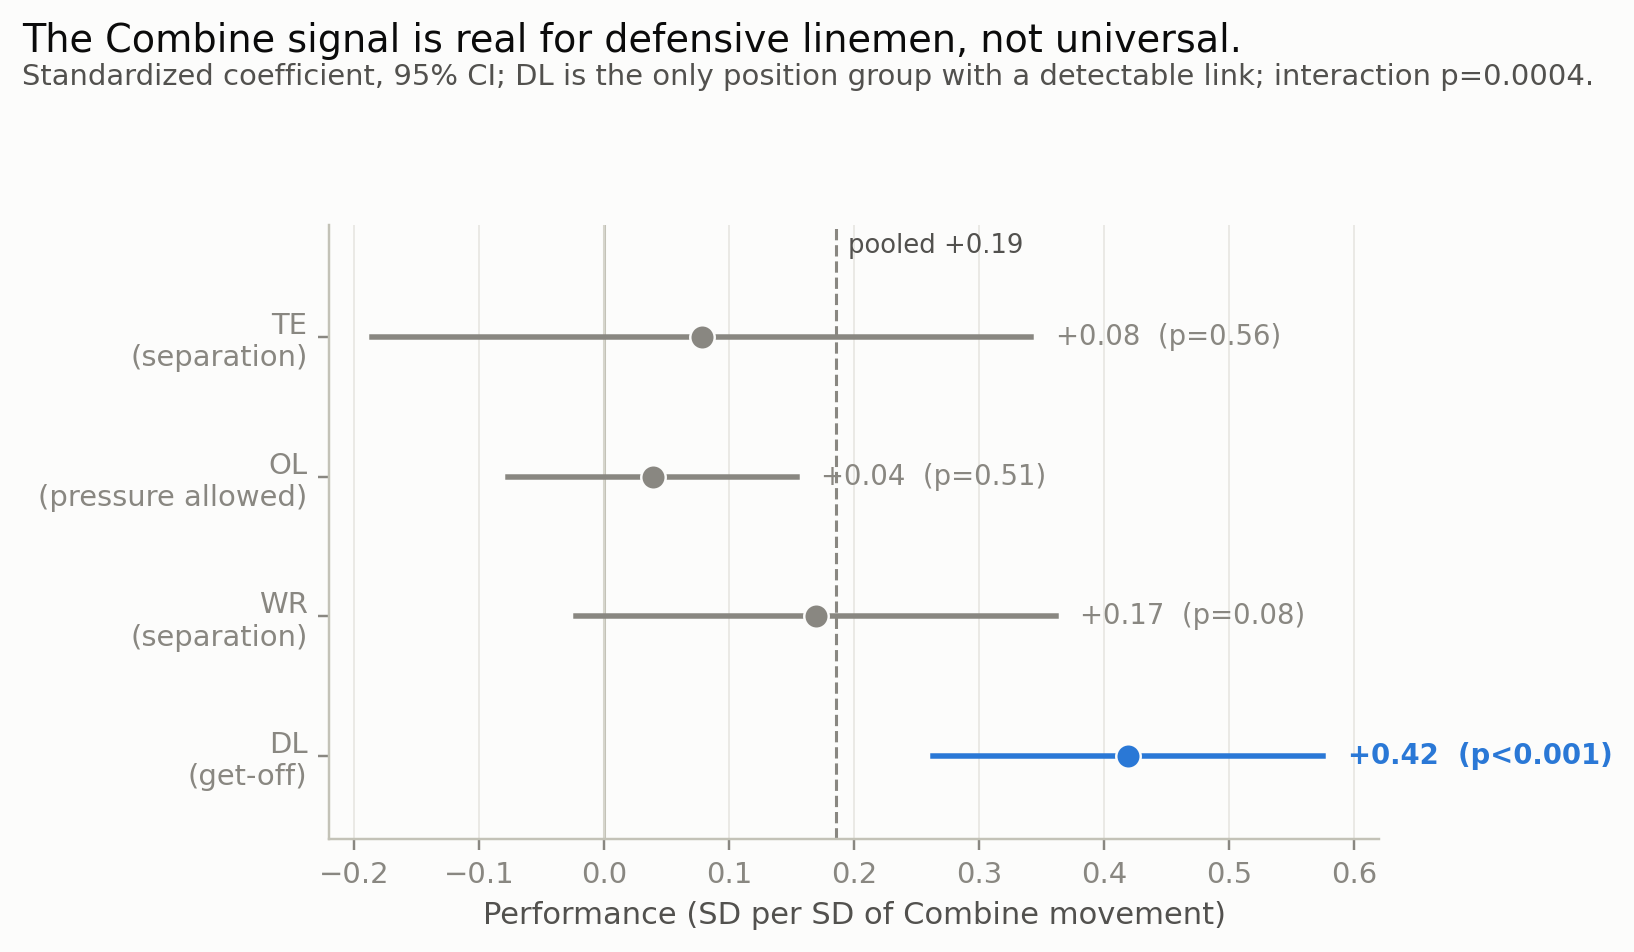

net_rent.png


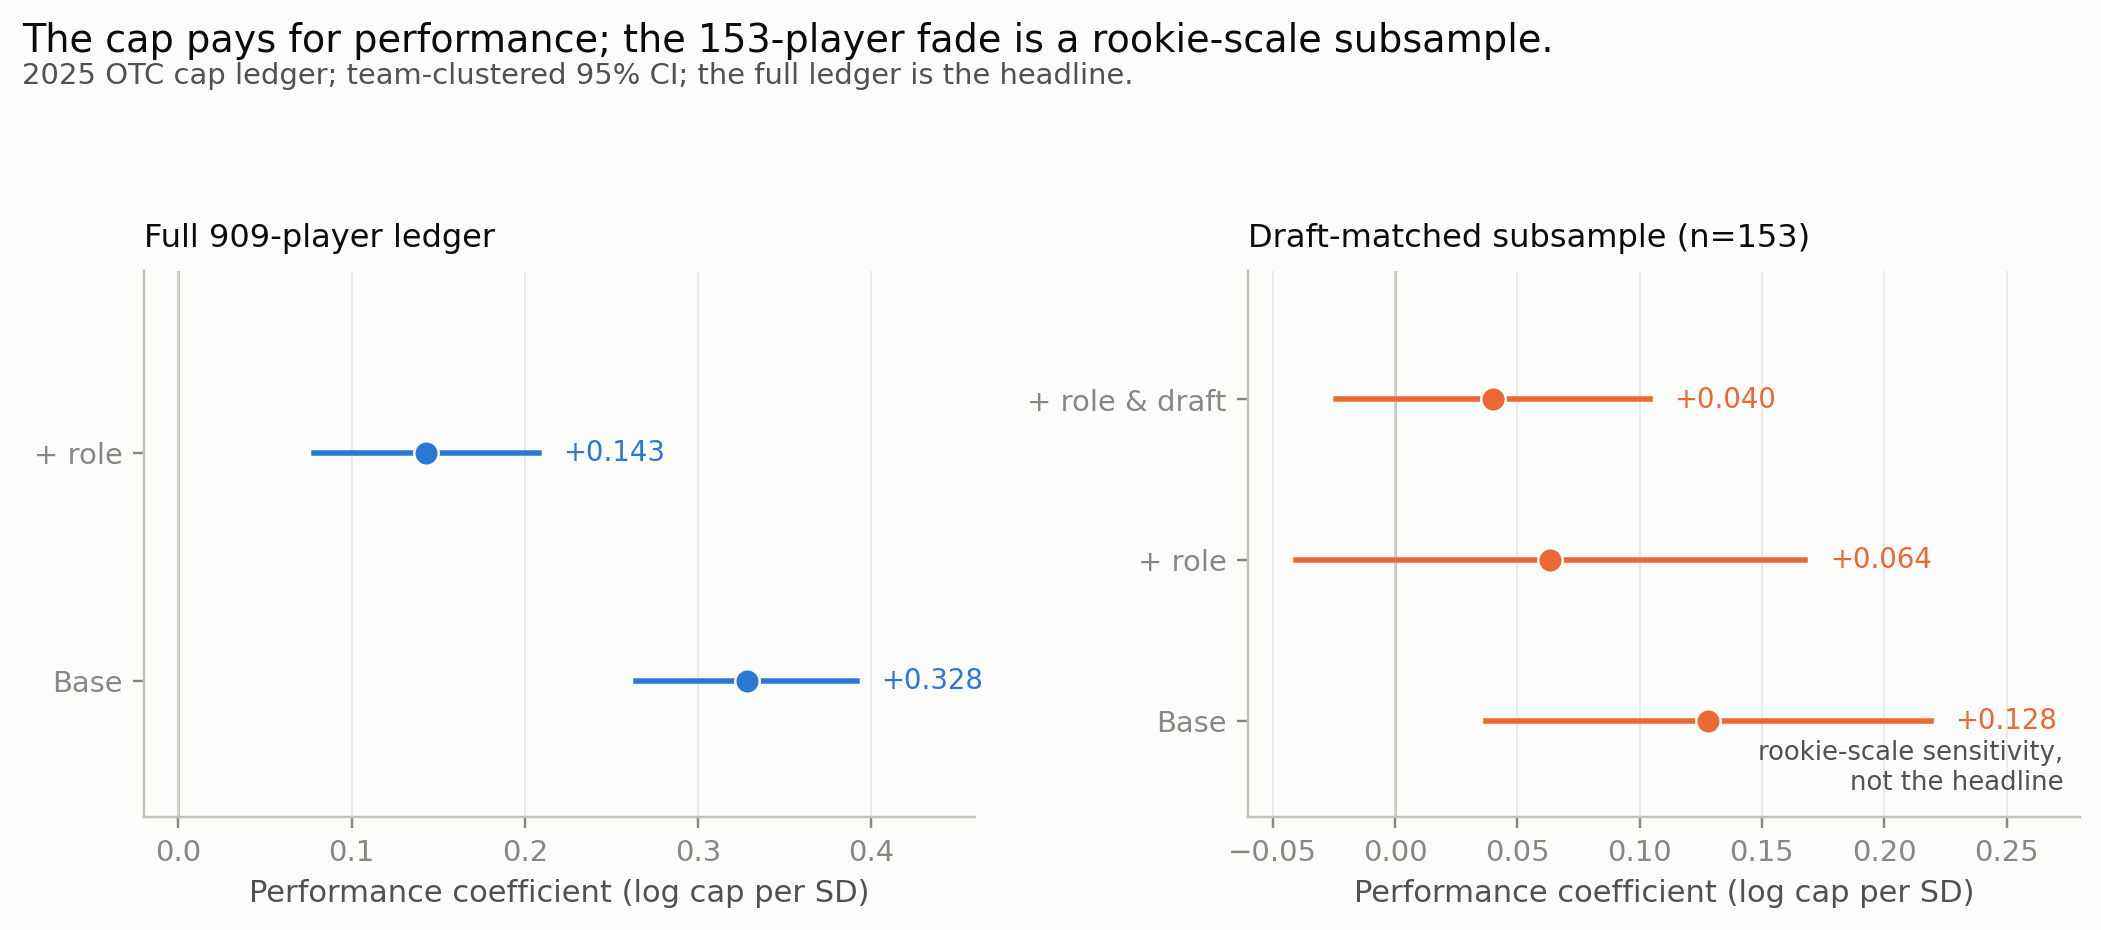

next_role_forest.png


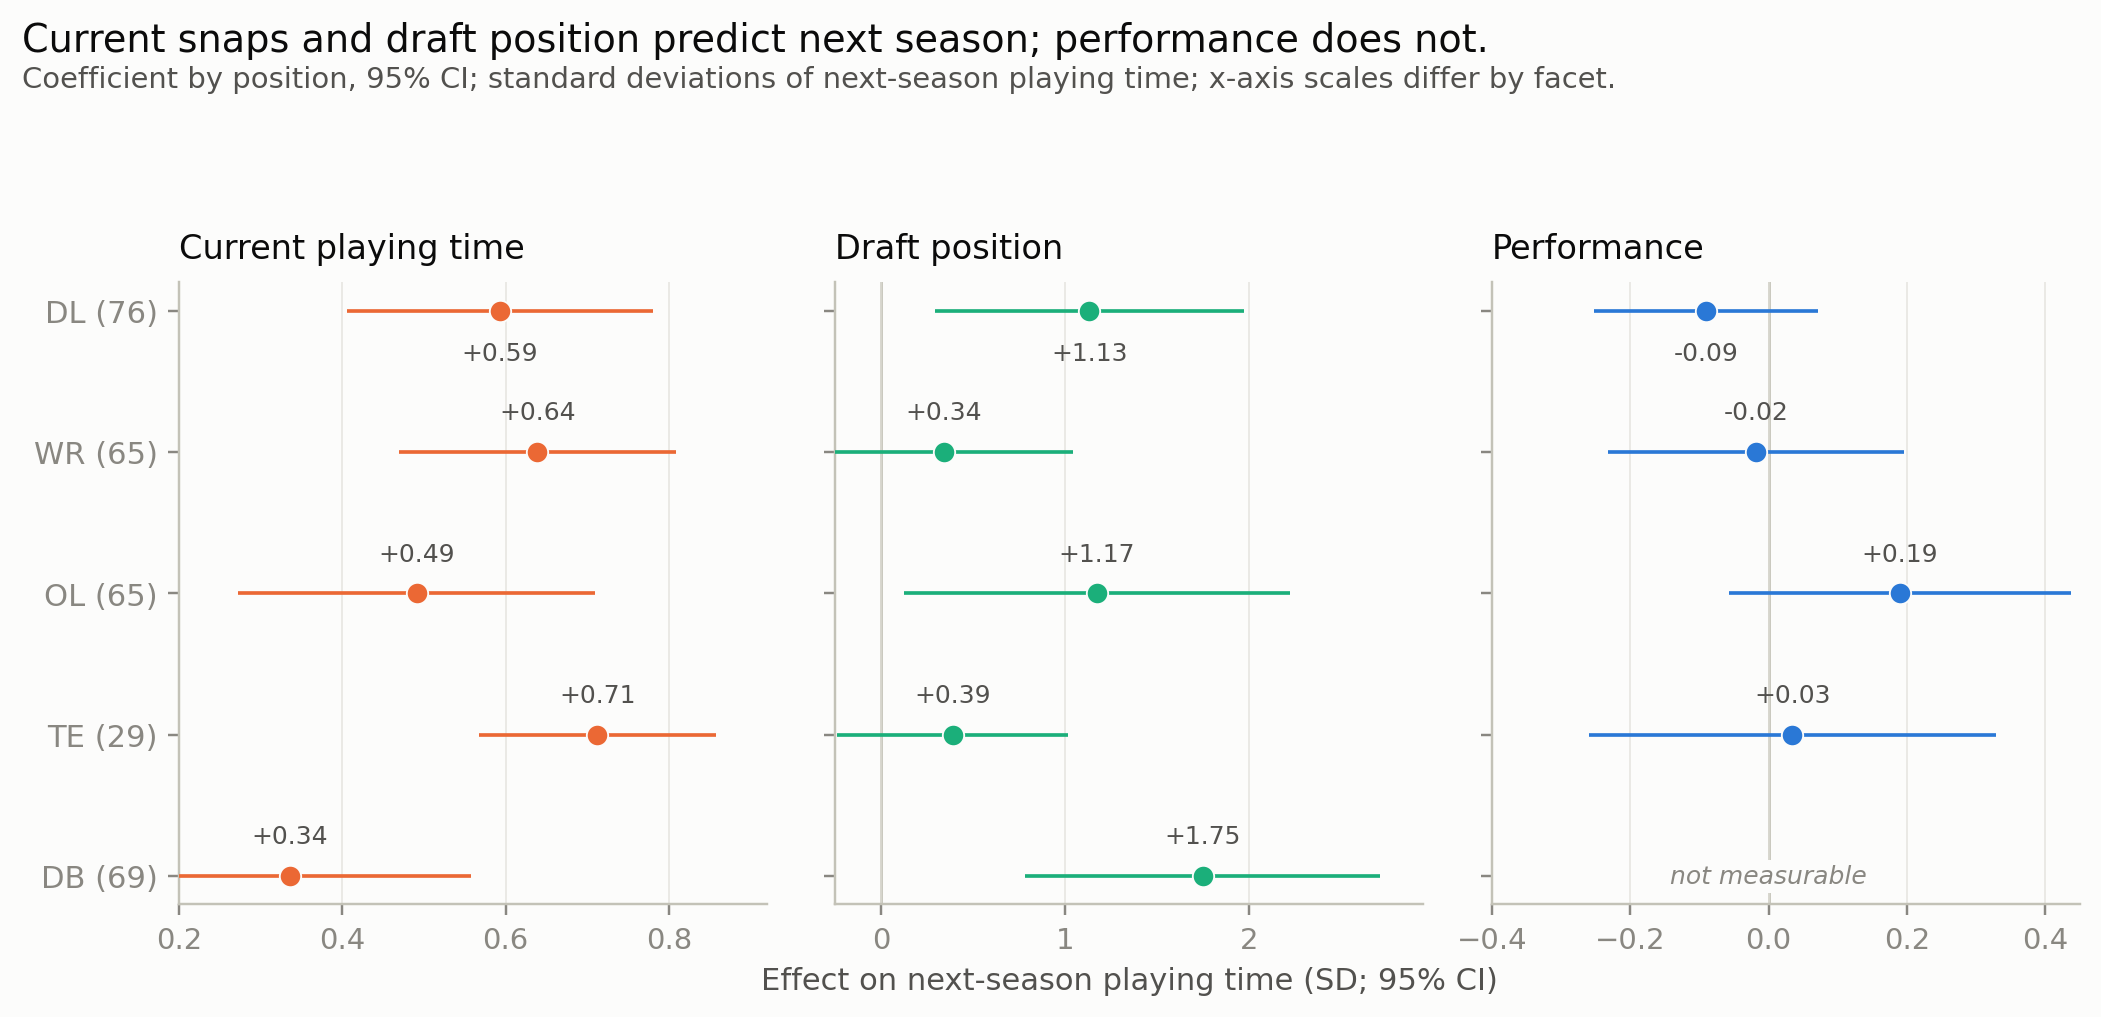

persistence_within_player.png


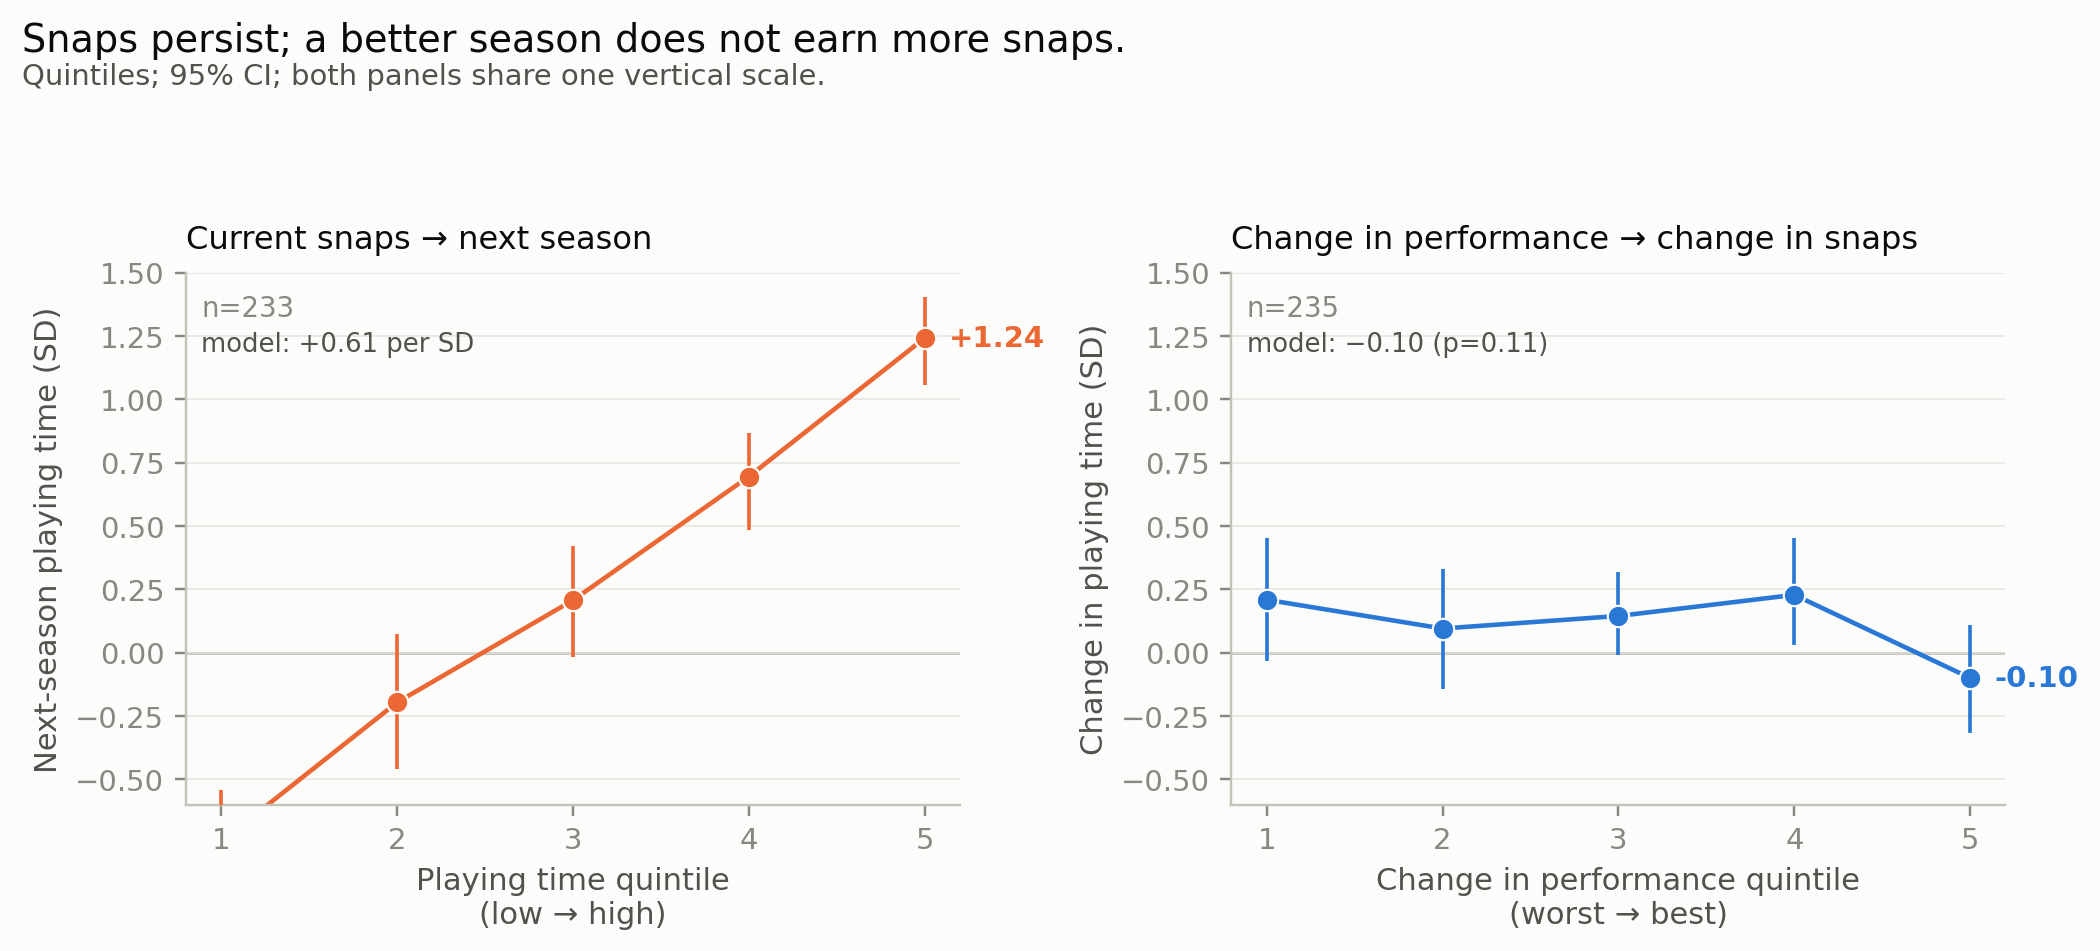

allocation_gap.png


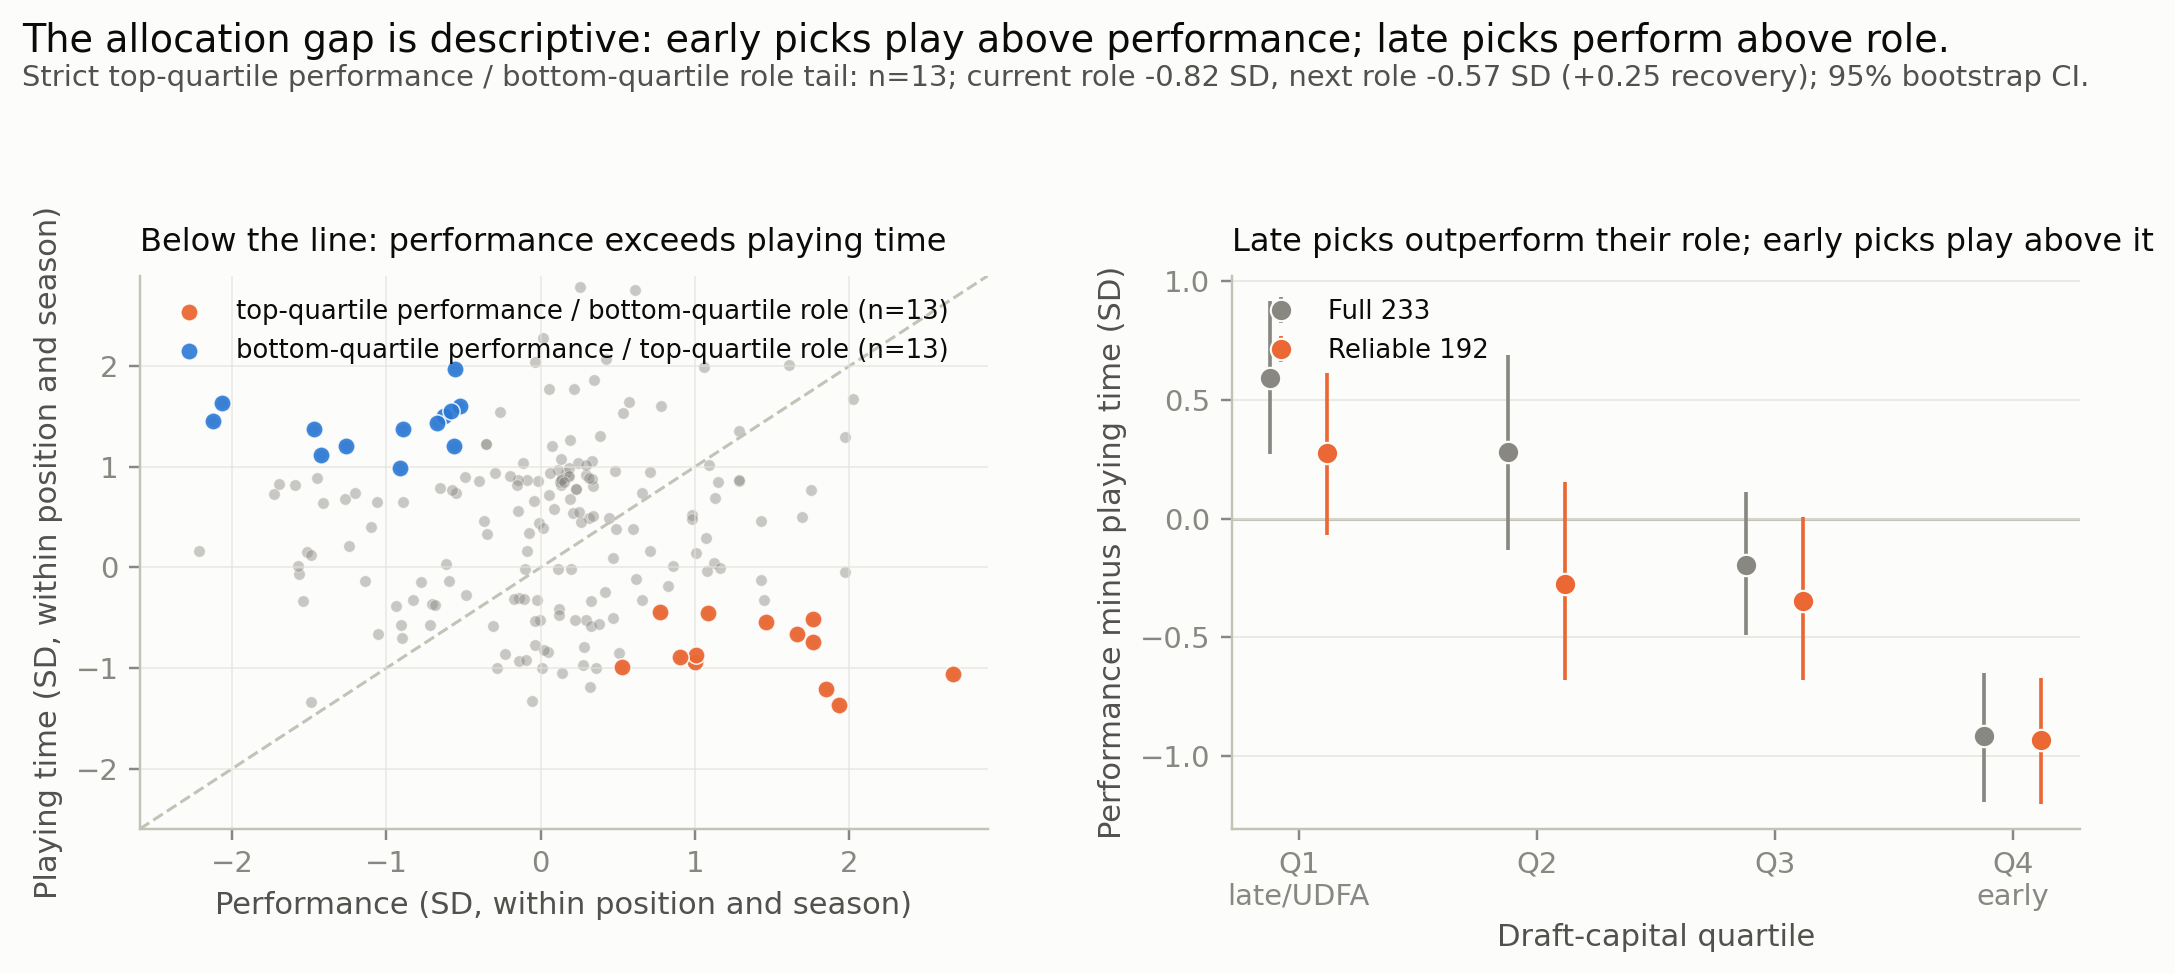

In [6]:

import base64
from IPython.display import Image, display
FIG_B64 = {'combine_linkage.png': '...', 'net_rent.png': '...', 'next_role_forest.png': '...', 'persistence_within_player.png': '...', 'allocation_gap.png': '...'}
for name, b64 in FIG_B64.items():
    print(name)
    display(Image(data=base64.b64decode(b64)))


## Cost-risk layer: the cap model and the allocation gap

The 2025 cap ledger is modeled on performance, age, experience, and position on the full 909 players; adding playing time gives the role-controlled model. The 153-player draft-matched model adds draft capital as a rookie-scale sensitivity. The allocation gap is performance z minus role z. These are derived public-data aggregates embedded for self-containment; the full derivation is in `src/discovery/cost_risk.py` and `src/salary/rents.py`. All analyses are exploratory.


In [7]:

import base64, zlib, io
def _load(b64):
    return pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(b64)).decode()))
pay_full = _load("eJx1j0lqA0EMRfc5hQ8gG5VmnaZx7PIAHbdpO4Tk9FEFQlZZCT7vS0/Pvr7BYekneHQ4XKd5+Rjjcj1f4A43WAnelmOf4TY9C33AbXn2l3tfT9MX4I7JMyjIuRkLtYqQSZw8Ai3MuBIyYXZmIpJmqKOXzSgqEQwldtCdNsxiWMLVVPqWBBKzYGHX2uiqbLUdXvePPp3e5xkawZib4rb3ef/Z183cj+e+/hk2oQwsBVQlzPwx5LqqzkgYyTEijzYcSck4fFBUGZmnasi42nYqqc1MUkTZ0/q2fkkcfSWqfiomsmTR6zL/OvJ/jt8312HL")
pay_nested = _load("eJyVkk2O2zAMhfdzihxACfhPEbObiwRuojQD2HHguCgwpx/KTYEuU2ghiHh6/PjAtS1TOc3tUh6tnD6P4/y7X9fPn9dyL7eyUJnmcxvL7bim9FFu89re7m25HL8KHJAqahBYqJFAzRKIsStyrQw1AHuJnUwNNHWmSFkiDFCqUKtQCqWrQB09uAqmB3BB5d4iAJjQldndUvljSFSEsrZh2p/GX48Ea+f33XkZLut+GtbTtZ13j2G6j/+QgrGKA7MJGlbvJWUUSqqo7i5U9p0eDEKcWLNvRAcwz3/KYUIk3pmIMVkYCSkqcTxRSQEl0PIzsBmWZR4TFf8XlSMqG6axWrUtGybPlKHHqia6oZKguFbPw7GlmsEhSkUyC0/czpTR5biKOSWl7xM1PYw8e2goCuuGety4Slq9BPzxV38QIE4zcYlaEfgPioJibkC4oHqqMFwlX2De59EsGeRYpCp9vuAiB7NcAs7lgBRF2wu+Rvz2Dcc0tSI=")
gap_groups = _load("eJxdkc1qAjEUhfc+hQ+Q2vv/syyU7l10PUxxLMIoau2ib98baWEwgRA+zuGek+yu4/42XNqpHafxNHyO57rsDn/Xr/F4nqfVFtfzeJue31/fXppmg40ms0ZooqkzF4lwTnZXMPBIa/vveR6IebWlplEKCgBjQnGOENFCHJaqSR6kLuQLEzej9gQbTCNLjGDzOrMzIkUCQjezwKSFTdbTeJ1/mkoXJiqwJGKNdKtQxTxdshZSBZdYeJctpbckr4KSUMlRRYqYgfXOwIXI2nWaD+PHPA2VohcVv+dzUXKTEmP2WsXqXdINNKg2Jj5YuSl2GUt/D8JMY9DUziSYK4JBogfSg/O/sdy19S9mKp7pUJWjs/oZAa7EoGpBD6N/AfPZfLM=")
gap_tails = _load("eJyVkEFOAzEMRfc9xRzAHRw7tpMtFxmlJUWVMp0hTSW4PZmirhAgpCiLrx+9/3JN81oytHQucIG1pI9crzDndJle0wqX/N6muvTGPXqeXmo6td3pVspEzNCWdVhzPS11TpdjHlqux3PJw9NwWFpb5mF7+0iBCSgCjWhBnKGPqBTVwx5HCc6LIVskb9F7wJGciAQ2DF/nZ+rbLdX2HfuIwRk46VwRoyDKGIN3BHs3IpFjCuyFOkrchuU+IAoKBzOPuqu5nNOh5MlF+qcwMZADN5oElU7tGhid6GZMXc4Zm/YBhn1fj9RH6SXXOxzZfkf/ac3QJakLBR/N1KKhqIX7d5tnRmXVoF43tPesEvFx7z4BB/+a9A==")
print("Full-ledger cap model (performance coefficient):")
print(pay_full.round(3).to_string(index=False))
print("\nDraft-matched sensitivity (n=153):")
print(pay_nested.round(3).to_string(index=False))
print("\nAllocation gap by draft quartile:")
print(gap_groups.round(2).to_string(index=False))
print("\nAllocation gap tails:")
print(gap_tails.round(2).to_string(index=False))


Full-ledger cap model (performance coefficient):
  term  coef    se  ci_low  ci_high   p   n    r2     model  n_terms                   note
perf_z 0.328 0.032   0.264    0.392 0.0 909 0.438 base_full       12 full 909-player ledger
perf_z 0.143 0.033   0.078    0.208 0.0 908 0.522 role_full       13 full 909-player ledger

Draft-matched sensitivity (n=153):
   term  coef    se  ci_low  ci_high     p   n    r2      model  n_terms                                 note
 perf_z 0.128 0.046   0.037    0.219 0.006 153 0.190       base       10 team-clustered; draft-matched sample
 perf_z 0.064 0.053  -0.041    0.168 0.232 153 0.250       role       11 team-clustered; draft-matched sample
 perf_z 0.040 0.033  -0.024    0.104 0.222 153 0.646 role_draft       12 team-clustered; draft-matched sample
B_draft 1.402 0.105   1.198    1.607 0.000 153 0.646 role_draft       12                                  NaN

Allocation gap by draft quartile:
     draft_q  n  mean_gap  median_gap       sample
Q1 

## Week-to-week check

Next-week role is predicted by this-week role, not by this-week performance. Early-season performance also does not predict late-season role after controlling for early role. The data do not identify an optimal review cadence; a monthly review is a process choice, not a tested rule. The result table is embedded below; the derivation is in `src/discovery/weekly_role.py`.


In [8]:

import base64, zlib, io
WEEKLY_B64 = "eJxtks1q3EAQhO95lrHp/+655kXE4p21TeSsWS+Y5OldM2swxDkIDa2SvqpqvZyPY2/XcXlpD+dxam+jPTxv+/l93p6eH5/aa/v9432MX/ufbR+H47YfHtvlvI/tb6P7dHEWrzL1KAyIs7uWJuPS7FPDqYKBcUKaMUeVSWwhScQkNl9sWuXfSK/jcgLpDgLy4jIzN2H1xaLoVCTc8eluSyWRKaRcpGnRl8yhZ5OpyeXSC2iAq5daD/s/++d2vBxOV+iZQ6dTBCHkWkHdnUgUwwwmniNCHRyukk7JipEITuXBGhFkc0QaDEGyC4V7v7HH4TLRh+tot+NXxYaUIeRkpO6y2JzUgzuyotxpJ7SrpbCgo1JKjMqEzLmnBFf2bHzvFmyqBDOW6GLcWTQp+Y7/7H2FqgnBpip0sWAkBGc4UsNqV+/QuBnSE1zyqqPSelafbqeDZSk0TARXMJP+y/5qnDoUgd7SjKrmHtEhqhZgkT46T+yEeq/CVoCV6U4DD7GWwj/gtyYMa0YE/DmBtrQv7Ad6Ibdi"
weekly = pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(WEEKLY_B64)).decode()))
print("Weekly lead-lag (next-week role):")
print(weekly.query("model == 'weekly_lead_lag'")[["term", "coef", "ci_low", "ci_high", "p", "n"]].round(3).to_string(index=False))
print("\nEarly-season -> late-season role:")
print(weekly.query("model == 'early_late'")[["term", "coef", "ci_low", "ci_high", "p", "n"]].round(3).to_string(index=False))


Weekly lead-lag (next-week role):
   term   coef  ci_low  ci_high     p    n
 role_z  0.753   0.717    0.788 0.000 3885
 perf_z -0.006  -0.027    0.015 0.586 3885
B_draft  0.116   0.008    0.225 0.036 3885

Early-season -> late-season role:
        term  coef  ci_low  ci_high     p   n
early_role_z 0.741   0.639    0.842 0.000 282
early_perf_z 0.008  -0.072    0.087 0.846 282
     B_draft 0.093  -0.175    0.361 0.498 282


## Cost-risk appendix: sources and limits

- **OTC positional spending** (2023–2025) and the archived 2025 OTC active-roster cap pages are the salary sources; nflverse supplies snaps, rosters, stats, and schedules.
- The 2025 cap snapshot matches 99.3% of active-cap dollars to a 2025 snap on player ID and team. The 909-player rent sample covers 68.7% of active-cap dollars; offensive linemen and specialists are excluded.
- **Cap model.** The full 909-player model is the headline; the 153-player draft-matched model is a rookie-scale sensitivity. The residual is descriptive, not a causal rent: cap hits reflect proration, restructures, timing, and expected future performance. Draft capital is partly the rookie wage scale.
- The allocation gap is descriptive; the strict tail is 12 players. The salary performance measure is nflverse public production, not the NGS `player_play` residual.
- **Soccer** uses UEFA 2025, Deloitte Money League 2025, club annual reports, and official league tables; accounting scopes and season windows differ. The table is illustrative, not a natural experiment.

Full source notes: `docs/EXTERNAL_DATA.md` and `docs/SOCCER_DATA.md`.


## Formal appendix: what is identified

- **Combine linkage:** the 10 Hz movement composite is tested against the tracking-derived performance residual. The pooled coefficient is positive, but position-specific models show it is a defensive-line result: DL +0.734, WR +0.366 (p=0.084), OL +0.058, TE +0.093; interaction p=0.0004. The DL outcome is get-off.
- **Role persistence:** next-season role is modeled as a function of current role, the performance residual, draft capital, position, and season, with cluster-robust standard errors. The performance coefficient is near zero; role and draft capital are positive. Leave-one-player-out R² and within-player changes are reported as validation.
- **Cost-risk:** the full-ledger cap model and the performance-role gap are exploratory; the 153-player draft-matched model is a rookie-scale sensitivity. The predictability lens does not survive role controls.
- **What is not identified:** causal effects of coaches, teams, schemes, injuries, or contracts. Role is snaps per appearance, not full depth-chart share. The role gap is a diagnostic. DB performance is unidentifiable and excluded from pooled models.


## Reproduce

- Data: NFL Big Data Bowl 2027, CC BY-NC 4.0. On Kaggle the notebook reads `/kaggle/input/nfl-big-data-bowl-2027/`; locally it reads `data/raw`.
- Salary panel: embedded as a compressed CSV derived from public OverTheCap positional spending (2023–2025), nflverse snaps/rosters/stats/schedules, and archived OTC 2025 team cap pages. The derivation is in `src/salary/`; sources and limits are in `docs/EXTERNAL_DATA.md`.
- Week-to-week check: embedded result table derived from the weekly tracking residuals; the derivation is in `src/discovery/weekly_role.py`.
- Main text: `writeup/submission.md`.
- Figures are written to `figures/`.
- The analysis is observational; see the limitations in the writeup.
